In [1]:
%matplotlib widget

import sys, os
sys.path.insert(0, os.getcwd())

import json
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from sklearn.decomposition import PCA

from network import LeakyRNN
from task import generate_trials


In [2]:
# ── Model directory and checkpoint ────────────────────────────────────────────
RESULTS_DIR = Path(os.environ.get('TONE_RESULTS_DIR', 'results'))
model_dir      = RESULTS_DIR / 'pure/pure_0_lr5e-06_bs128_noise0.5'
checkpoint_num = None   # None → checkpoint.pkl (final); int → checkpoint_{n}.pkl

# ── Trials per condition (for hidden-state trajectories) ─────────────────────
n_trials = 128

# ── Derived paths ─────────────────────────────────────────────────────────────
ckpt_fname = f'checkpoint_{checkpoint_num}.pkl' if checkpoint_num else 'checkpoint.pkl'
ckpt_path  = model_dir / ckpt_fname
save_dir   = model_dir
print(f'Checkpoint : {ckpt_path}')
print(f'Plots saved: {save_dir}')

Checkpoint : results\pure\pure_0_lr5e-06_bs128_noise0.5\checkpoint.pkl
Plots saved: results\pure\pure_0_lr5e-06_bs128_noise0.5


In [3]:
# ── Load config.json and train_params.json from model directory ───────────────
with open(model_dir / 'config.json') as f:
    config = json.load(f)
with open(model_dir / 'train_params.json') as f:
    train_params = json.load(f)

# 'task_list' in modern configs (main & transfer); 'tasks' in old format
task_list   = config.get('task_list', config.get('tasks', []))
task_params = config['task_params']
hp          = config['training']          # model + optimiser hyperparameters
# 'train_task' in main training config; 'task_type' in transfer config
task_type   = config.get('train_task', config.get('task_type', task_list[0]))

# Timing
t_p         = task_params['timing']
dt          = t_p['dt']
stim_on     = config.get('stim_on',  int(t_p['pre_stim_dur_ms'] / dt))
stim_off    = config.get('stim_off', stim_on + t_p['n_pulses'] *
                         max(1, int(np.ceil(t_p['pulse_dur_ms'] / dt))))
pulse_steps = config.get('pulse_steps',
              max(1, int(np.ceil(t_p['pulse_dur_ms'] / dt))))

# alpha = dt / tau  (LeakyRNN parameter)
alpha = dt / hp['model']['tau']
n_rnn = hp['model']['n_rnn']

print(f'task_type   : {task_type}')
print(f'task_list   : {task_list}')
print(f'stim_on={stim_on}  stim_off={stim_off}  pulse_steps={pulse_steps}  dt={dt}ms')
print(f'Model       : n_rnn={n_rnn}  tau={hp["model"]["tau"]}ms  alpha={alpha:.3f}')

# ── Load checkpoint ───────────────────────────────────────────────────────────
with open(ckpt_path, 'rb') as f:
    ckpt = pickle.load(f)

params = ckpt['params']
print(f'\nLoaded step {ckpt["step"]}')

# ── Run model (no noise) on test trials ───────────────────────────────────────
model = LeakyRNN(
    n_rnn     = n_rnn,
    n_out     = 1,
    alpha     = alpha,
    sigma_rec = hp['model']['sigma_rec'],
    sigma_x   = hp['model']['sigma_x'],
)

trial = generate_trials(task_type, task_list, mode='test',
                        batch_size=n_trials, rng=np.random.default_rng(1))
xs    = jnp.array(trial.x)
_, hs_jax = model.apply({'params': params}, xs,
                         noise_input=False, noise_rec=False,
                         rngs={'noise': jax.random.PRNGKey(0)})
hs = np.array(hs_jax)   # (tdim, batch, n_rnn)

go_mask   = trial.is_go
nogo_mask = ~trial.is_go
print(f'Trials: {go_mask.sum()} Go, {nogo_mask.sum()} No-Go')

task_type   : pure
task_list   : ['pure', 'harmonic', 'wn']
stim_on=50  stim_off=90  pulse_steps=5  dt=10ms
Model       : n_rnn=128  tau=100ms  alpha=0.100



Loaded step 15000
Trials: 64 Go, 64 No-Go


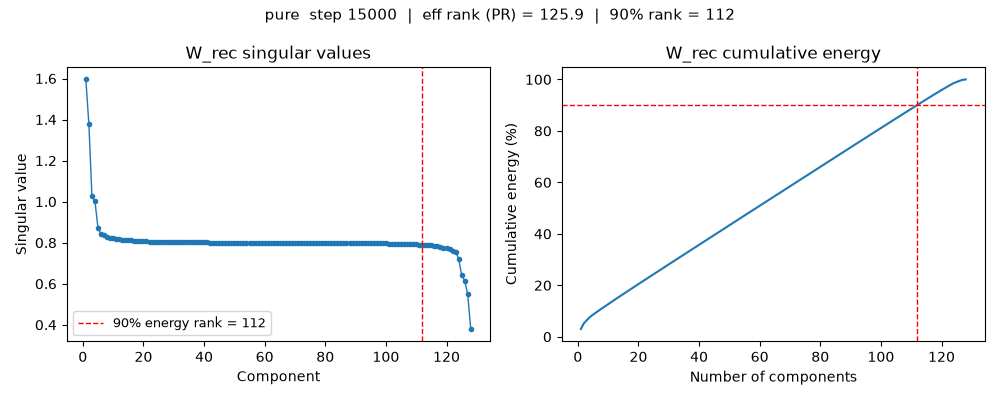

Saved: results\pure\pure_0_lr5e-06_bs128_noise0.5\rank_analysis_15000.png
Effective rank (participation ratio): 125.91
90% energy rank: 112


In [4]:
# ── Rank analysis of W_rec ────────────────────────────────────────────────────
W_rec = np.array(params['W_rec'])   # (n_rnn, n_rnn)
sv    = np.linalg.svd(W_rec, compute_uv=False)   # singular values, descending

# Effective rank: participation ratio of singular values
sv_norm     = sv / sv.sum()
eff_rank_pr = 1.0 / (sv_norm ** 2).sum()

# 90% energy rank
cumvar_sv = np.cumsum(sv ** 2) / (sv ** 2).sum()
rank_90   = int(np.searchsorted(cumvar_sv, 0.90)) + 1

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
ax.plot(np.arange(1, len(sv) + 1), sv, 'o-', markersize=3, lw=1)
ax.axvline(rank_90, color='red', lw=1, ls='--', label=f'90% energy rank = {rank_90}')
ax.set_xlabel('Component')
ax.set_ylabel('Singular value')
ax.set_title('W_rec singular values')
ax.legend(fontsize=9)

ax = axes[1]
ax.plot(np.arange(1, len(sv) + 1), cumvar_sv * 100, lw=1.5)
ax.axhline(90, color='red', lw=1, ls='--')
ax.axvline(rank_90, color='red', lw=1, ls='--')
ax.set_xlabel('Number of components')
ax.set_ylabel('Cumulative energy (%)')
ax.set_title('W_rec cumulative energy')

fig.suptitle(
    f'{task_type}  step {ckpt["step"]}  |  '
    f'eff rank (PR) = {eff_rank_pr:.1f}  |  90% rank = {rank_90}',
    fontsize=11)
plt.tight_layout()
out = save_dir / f'rank_analysis_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')
print(f'Effective rank (participation ratio): {eff_rank_pr:.2f}')
print(f'90% energy rank: {rank_90}')

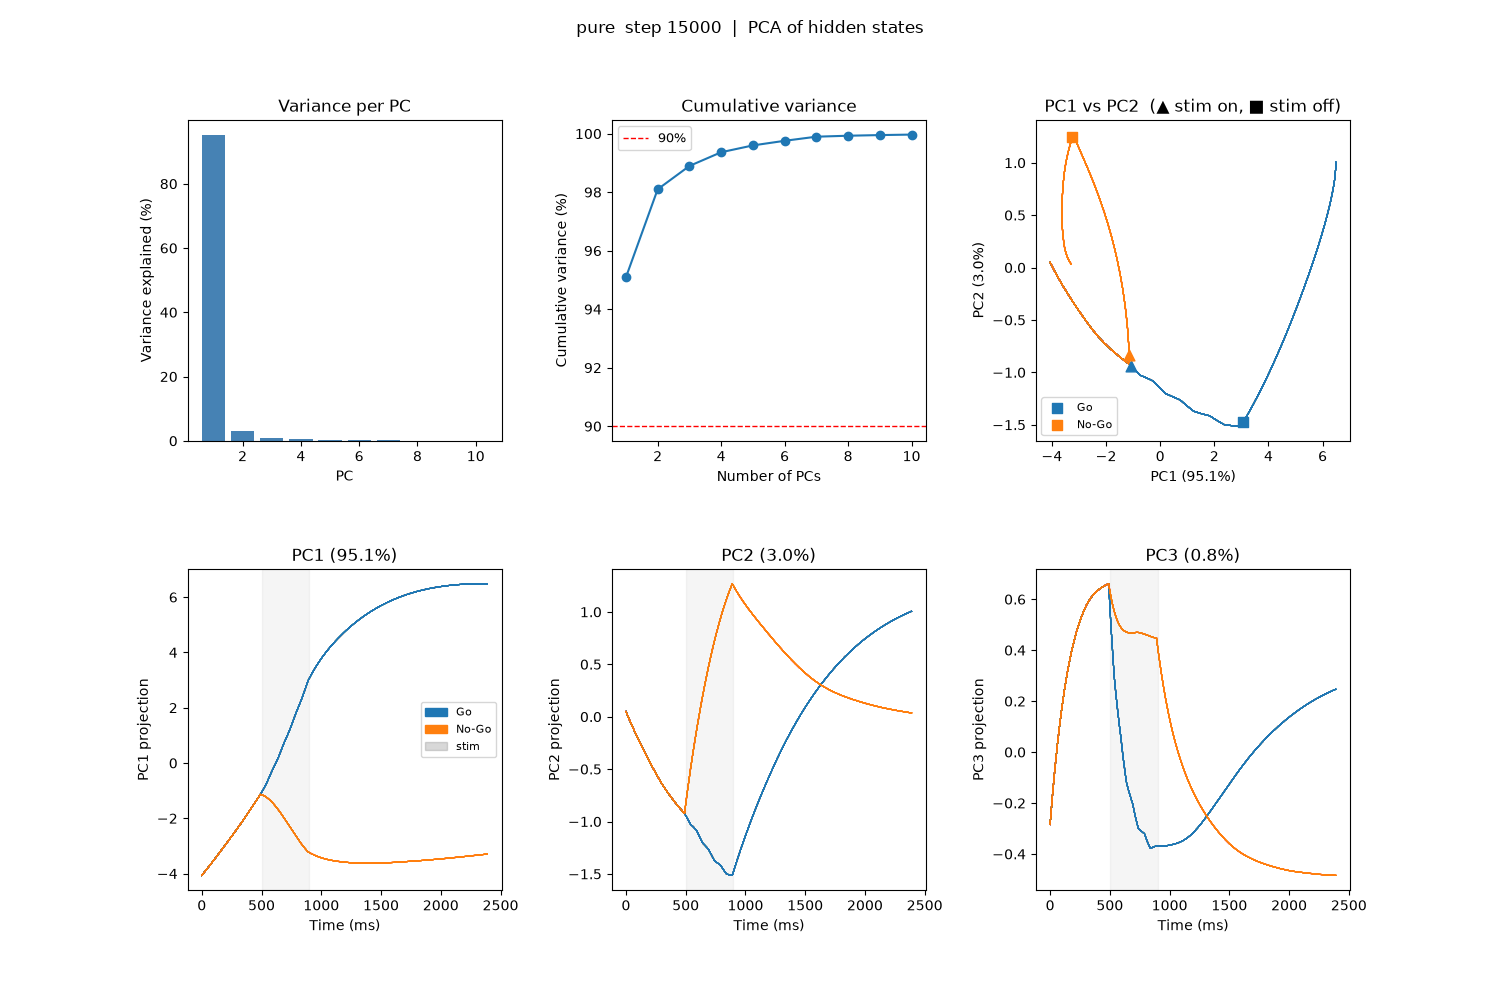

Saved: results\pure\pure_0_lr5e-06_bs128_noise0.5\pca_analysis_15000.png
PCs to reach 90% variance: 1


In [5]:
# ── PCA of hidden-state trajectories ─────────────────────────────────────────
tdim    = hs.shape[0]
hs_flat = hs.reshape(-1, n_rnn)   # (tdim * batch, n_rnn)
n_pcs   = min(10, n_rnn)
pca     = PCA(n_components=n_pcs)
pca.fit(hs_flat)

var_exp    = pca.explained_variance_ratio_ * 100
cumvar_pca = np.cumsum(var_exp)
t_axis     = np.arange(tdim) * dt   # ms

COND_COLOR = {'go': 'tab:blue', 'nogo': 'tab:orange'}

fig = plt.figure(figsize=(15, 10))
gs  = fig.add_gridspec(2, 3, hspace=0.4, wspace=0.35)

# (0,0) Variance per PC
ax = fig.add_subplot(gs[0, 0])
ax.bar(np.arange(1, n_pcs + 1), var_exp, color='steelblue')
ax.set_xlabel('PC')
ax.set_ylabel('Variance explained (%)')
ax.set_title('Variance per PC')

# (0,1) Cumulative variance
ax = fig.add_subplot(gs[0, 1])
ax.plot(np.arange(1, n_pcs + 1), cumvar_pca, 'o-', lw=1.5)
ax.axhline(90, color='red', lw=1, ls='--', label='90%')
ax.set_xlabel('Number of PCs')
ax.set_ylabel('Cumulative variance (%)')
ax.set_title('Cumulative variance')
ax.legend(fontsize=9)

# (0,2) PC1 vs PC2 phase portrait
ax = fig.add_subplot(gs[0, 2])
for i in np.where(go_mask)[0]:
    p = pca.transform(hs[:, i, :])
    ax.plot(p[:, 0], p[:, 1], color=COND_COLOR['go'],   alpha=0.25, lw=0.8)
for i in np.where(nogo_mask)[0]:
    p = pca.transform(hs[:, i, :])
    ax.plot(p[:, 0], p[:, 1], color=COND_COLOR['nogo'], alpha=0.25, lw=0.8)
for mask, color, label in [(go_mask, COND_COLOR['go'], 'Go'),
                            (nogo_mask, COND_COLOR['nogo'], 'No-Go')]:
    idx = np.where(mask)[0]
    ax.scatter(*pca.transform(hs[stim_on,  idx, :]).mean(0)[:2], s=60,
               color=color, marker='^', zorder=5)
    ax.scatter(*pca.transform(hs[stim_off, idx, :]).mean(0)[:2], s=60,
               color=color, marker='s', zorder=5, label=label)
ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)')
ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)')
ax.set_title('PC1 vs PC2  (▲ stim on, ■ stim off)')
ax.legend(fontsize=8)

# (1,0-2) PC1/2/3 time-courses
from matplotlib.patches import Patch
for pc_idx in range(3):
    ax = fig.add_subplot(gs[1, pc_idx])
    for i in np.where(go_mask)[0]:
        ax.plot(t_axis, pca.transform(hs[:, i, :])[:, pc_idx],
                color=COND_COLOR['go'],   alpha=0.2, lw=0.8)
    for i in np.where(nogo_mask)[0]:
        ax.plot(t_axis, pca.transform(hs[:, i, :])[:, pc_idx],
                color=COND_COLOR['nogo'], alpha=0.2, lw=0.8)
    ax.axvspan(stim_on * dt, stim_off * dt, alpha=0.08, color='gray')
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel(f'PC{pc_idx+1} projection')
    ax.set_title(f'PC{pc_idx+1} ({var_exp[pc_idx]:.1f}%)')
    if pc_idx == 0:
        ax.legend(handles=[
            Patch(color=COND_COLOR['go'],   label='Go'),
            Patch(color=COND_COLOR['nogo'], label='No-Go'),
            Patch(color='gray', alpha=0.3,  label='stim'),
        ], fontsize=8)

fig.suptitle(f'{task_type}  step {ckpt["step"]}  |  PCA of hidden states', fontsize=12)
out = save_dir / f'pca_analysis_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')
print(f'PCs to reach 90% variance: {int(np.searchsorted(cumvar_pca, 90)) + 1}')

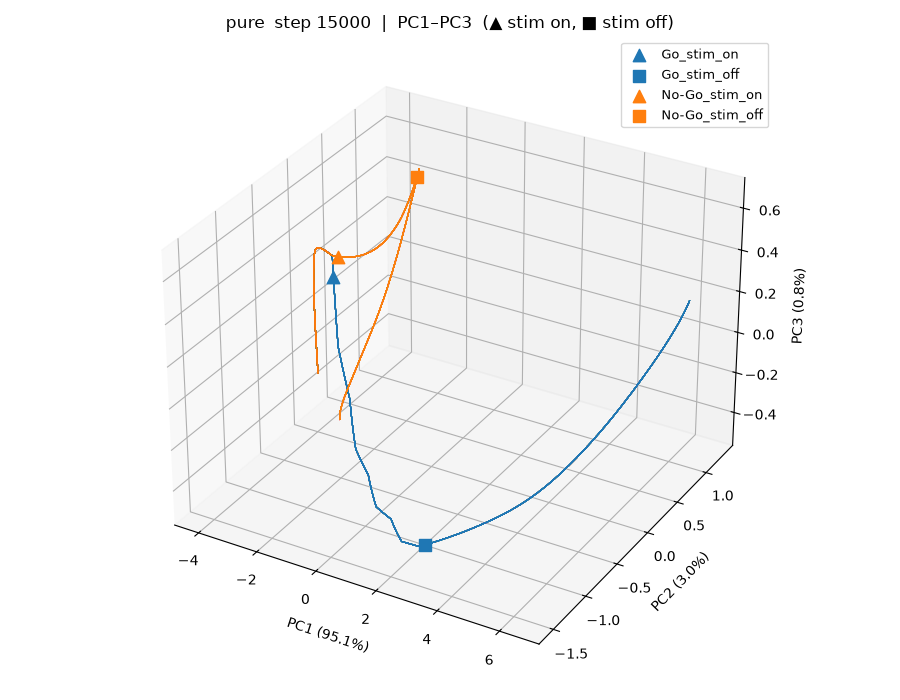

Saved: results\pure\pure_0_lr5e-06_bs128_noise0.5\pca3d_15000.png


In [6]:
# ── 3D PCA trajectory plot ────────────────────────────────────────────────────
fig = plt.figure(figsize=(9, 7))
ax  = fig.add_subplot(111, projection='3d')

for i in np.where(go_mask)[0]:
    p = pca.transform(hs[:, i, :])
    ax.plot(p[:, 0], p[:, 1], p[:, 2], color=COND_COLOR['go'],   alpha=0.25, lw=0.8)
for i in np.where(nogo_mask)[0]:
    p = pca.transform(hs[:, i, :])
    ax.plot(p[:, 0], p[:, 1], p[:, 2], color=COND_COLOR['nogo'], alpha=0.25, lw=0.8)

# Mark stim_on and stim_off (mean across trials per condition)
for mask, color, label in [(go_mask, COND_COLOR['go'], 'Go'),
                            (nogo_mask, COND_COLOR['nogo'], 'No-Go')]:
    idx = np.where(mask)[0]
    m_on  = pca.transform(hs[stim_on,  idx, :]).mean(0)
    m_off = pca.transform(hs[stim_off, idx, :]).mean(0)
    ax.scatter(*m_on[:3],  s=80, color=color, marker='^', zorder=5, depthshade=False,
               label=f'{label}_stim_on')
    ax.scatter(*m_off[:3], s=80, color=color, marker='s', zorder=5, depthshade=False,
               label=f'{label}_stim_off')

ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)', labelpad=6)
ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)', labelpad=6)
ax.set_zlabel(f'PC3 ({var_exp[2]:.1f}%)', labelpad=6)
ax.set_title(f'{task_type}  step {ckpt["step"]}  |  PC1–PC3  (▲ stim on, ■ stim off)')
ax.legend(fontsize=9)

plt.tight_layout()
out = save_dir / f'pca3d_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')